## PROJET: Implémentation Manuelle et Automatisée d'un Arbre de Décision
## Objectif : Comprendre le calcul mathématique de l'entropie et du gain d'information, puis utiliser l'algorithme CART (via rpart).

[1] "Gain d'information pour Météo: 0.0183107818200591"
[1] "Gain d'information pour Amis: 0.0727802257837327"
[1] "Gain d'information pour Vent: 0.378878837135229"
[1] "Gain d'information pour Jour: 0.0183107818200591"
n= 9 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

 1) root 9 3 non (0.6666667 0.3333333)  
   2) Vent=fort 4 0 non (1.0000000 0.0000000) *
   3) Vent=faible 5 2 oui (0.4000000 0.6000000)  
     6) Amis=absents 3 1 non (0.6666667 0.3333333)  
      12) Jour=week-end 2 0 non (1.0000000 0.0000000) *
      13) Jour=semaine 1 0 oui (0.0000000 1.0000000) *
     7) Amis=présents 2 0 oui (0.0000000 1.0000000) *


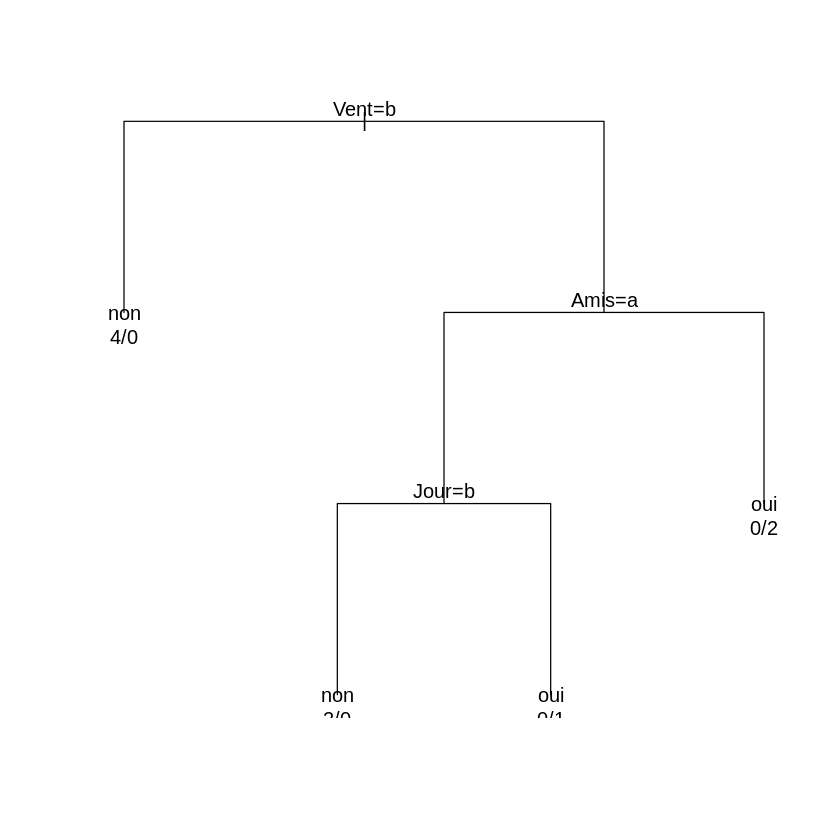

In [4]:
# Charger la bibliothèque nécessaire
library(rpart)

# Création des données
data <- data.frame(
  Meteo = c('soleil', 'soleil', 'soleil', 'soleil', 'nuages', 'nuages', 'nuages', 'nuages', 'soleil'),
  Amis = c('présents', 'absents', 'présents', 'absents', 'absents', 'présents', 'absents', 'présents', 'absents'),
  Vent = c('faible', 'fort', 'fort', 'faible', 'faible', 'fort', 'fort', 'faible', 'faible'),
  Jour = c('week-end', 'semaine', 'semaine', 'semaine', 'week-end', 'week-end', 'semaine', 'week-end', 'week-end'),
  Decision = c('oui', 'non', 'non', 'oui', 'non', 'non', 'non', 'oui', 'non')
)

# Visualiser les données
#print(data)

# Fonction pour calculer l'entropie
entropie <- function(p) {
  if (p == 0 || p == 1) {
    return(0)
  } else {
    return(-p * log2(p) - (1 - p) * log2(1 - p))
  }
}

# 1. Calcul de l'entropie de la variable cible "Decision"
total_oui <- sum(data$Decision == "oui")
total_non <- sum(data$Decision == "non")
p_oui <- total_oui / nrow(data)
p_non <- total_non / nrow(data)

# Entropie de la décision
entropie_decision <- entropie(p_oui)
#print(paste("Entropie de la décision:", entropie_decision))

# 2. Calcul du gain d'information pour l'attribut "Meteo"
# Entropie conditionnelle pour chaque valeur de Meteo
entropie_soleil <- entropie(sum(data$Meteo == "soleil" & data$Decision == "oui") / sum(data$Meteo == "soleil"))
entropie_nuages <- entropie(sum(data$Meteo == "nuages" & data$Decision == "oui") / sum(data$Meteo == "nuages"))

# Proportion de chaque valeur de l'attribut "Meteo"
p_soleil <- sum(data$Meteo == "soleil") / nrow(data)
p_nuages <- sum(data$Meteo == "nuages") / nrow(data)

# Gain d'information pour "Meteo"
gain_meteo <- entropie_decision - (p_soleil * entropie_soleil + p_nuages * entropie_nuages)
print(paste("Gain d'information pour Météo:", gain_meteo))

# 3. Calcul du gain d'information pour l'attribut "Amis"
entropie_amis_presents <- entropie(sum(data$Amis == "présents" & data$Decision == "oui") / sum(data$Amis == "présents"))
entropie_amis_absents <- entropie(sum(data$Amis == "absents" & data$Decision == "oui") / sum(data$Amis == "absents"))

p_amis_presents <- sum(data$Amis == "présents") / nrow(data)
p_amis_absents <- sum(data$Amis == "absents") / nrow(data)

gain_amis <- entropie_decision - (p_amis_presents * entropie_amis_presents + p_amis_absents * entropie_amis_absents)
print(paste("Gain d'information pour Amis:", gain_amis))

# 4. Calcul du gain d'information pour l'attribut "Vent"
entropie_vent_faible <- entropie(sum(data$Vent == "faible" & data$Decision == "oui") / sum(data$Vent == "faible"))
entropie_vent_fort <- entropie(sum(data$Vent == "fort" & data$Decision == "oui") / sum(data$Vent == "fort"))

p_vent_faible <- sum(data$Vent == "faible") / nrow(data)
p_vent_fort <- sum(data$Vent == "fort") / nrow(data)

gain_vent <- entropie_decision - (p_vent_faible * entropie_vent_faible + p_vent_fort * entropie_vent_fort)
print(paste("Gain d'information pour Vent:", gain_vent))

# 5. Calcul du gain d'information pour l'attribut "Jour"
entropie_jour_weekend <- entropie(sum(data$Jour == "week-end" & data$Decision == "oui") / sum(data$Jour == "week-end"))
entropie_jour_semaine <- entropie(sum(data$Jour == "semaine" & data$Decision == "oui") / sum(data$Jour == "semaine"))

p_jour_weekend <- sum(data$Jour == "week-end") / nrow(data)
p_jour_semaine <- sum(data$Jour == "semaine") / nrow(data)

gain_jour <- entropie_decision - (p_jour_weekend * entropie_jour_weekend + p_jour_semaine * entropie_jour_semaine)
print(paste("Gain d'information pour Jour:", gain_jour))

# 6. Construction de l'arbre de décision avec des paramètres ajustés
arbre <- rpart(Decision ~ Meteo + Amis + Vent + Jour, data = data, method = "class",
               control = rpart.control(minsplit = 2, cp = 0.01))

# Afficher l'arbre de décision
print(arbre)

# Plot de l'arbre
plot(arbre)
text(arbre, use.n = TRUE)